# Forecasting the Transition from Fossil Fuels to Renewable Energy

## 1. Import required libraries

This section imports the libraries used for file handling, data preparation, Ridge regression, validation metrics, and visualization.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Load and prepare the merged dataset

This section loads `CSV/merged.csv`, extracts energy-mix records, and combines them with yearly CO2 records using year and ISO3 country code.

In [7]:
notebook_dir = Path.cwd()
if (notebook_dir / "sample_data" / "merged.csv").exists():
    csv_path = notebook_dir / "sample_data" / "merged.csv"
elif (notebook_dir / "CSV" / "merged.csv").exists():
    csv_path = notebook_dir / "CSV" / "merged.csv"
else:
    csv_path = notebook_dir / "Data-Mining" / "CSV" / "merged.csv"

merged = pd.read_csv(csv_path, low_memory=False)
energy_columns = ["year", "country", "iso3", "region", "coal_pct", "oil_pct", "gas_pct", "nuclear_pct", "hydro_pct", "solar_pct", "wind_pct", "other_renewables_pct", "renewables_total_pct", "fossil_total_pct"]
energy = merged.loc[merged["source_file"].eq("energy_mix_yearly.csv"), energy_columns].copy()
co2_columns = ["year", "iso3", "co2_emissions_mt", "population_millions", "co2_per_capita_t", "co2_intensity_kg_per_gdp_usd"]
co2 = merged.loc[merged["source_file"].eq("co2_emissions_yearly.csv"), co2_columns].copy()
energy = energy.merge(co2, on=["year", "iso3"], how="left").sort_values(["country", "year"]).reset_index(drop=True)
print(f"Country-energy rows: {len(energy):,}; years: {energy.year.min()}-{energy.year.max()}; countries: {energy.country.nunique()}")

Country-energy rows: 1,350; years: 2000-2026; countries: 50


## 3. Create time-series lag features

This section creates one-year and two-year lag features for renewable, fossil, and individual fuel shares so the model can learn from previous energy-mix patterns.

In [8]:
lag_columns = ["renewables_total_pct", "fossil_total_pct", "coal_pct", "oil_pct", "gas_pct", "nuclear_pct", "hydro_pct", "solar_pct", "wind_pct"]
model_data = energy.copy()
for column in lag_columns:
    model_data[f"{column}_lag1"] = model_data.groupby("country", observed=True)[column].shift(1)
    model_data[f"{column}_lag2"] = model_data.groupby("country", observed=True)[column].shift(2)
feature_columns = ["year", "co2_emissions_mt", "population_millions", "co2_per_capita_t", "co2_intensity_kg_per_gdp_usd"]
feature_columns += [f"{column}_lag{i}" for i in (1, 2) for column in lag_columns]
model_data = model_data.dropna(subset=feature_columns + ["renewables_total_pct", "fossil_total_pct"])
print(f"Training-ready observations: {len(model_data):,}")

Training-ready observations: 1,250


##📌4. First model: Ridge Regression

This section trains Ridge regression models with country encoding and standardized numeric features. Data through 2023 is used for training, while 2024–2026 is held out for MAE, RMSE, and R² validation.

In [9]:
train = model_data[model_data.year <= 2023].copy()
test = model_data[(model_data.year >= 2024) & (model_data.year <= 2026)].copy()
targets = ["renewables_total_pct", "fossil_total_pct"]
models = {}
test_predictions = test[["country", "year"] + targets].copy()
preprocessor = ColumnTransformer([
    ("country", OneHotEncoder(handle_unknown="ignore"), ["country"]),
    ("numeric", StandardScaler(), feature_columns),
])
for target in targets:
    model = Pipeline([("preprocessor", preprocessor), ("regressor", Ridge(alpha=10.0))])
    model.fit(train[["country"] + feature_columns], train[target])
    test_predictions[f"predicted_{target}"] = np.clip(model.predict(test[["country"] + feature_columns]), 0, 100)
    models[target] = model
    actual = test_predictions[target]
    predicted = test_predictions[f"predicted_{target}"]
    print(f"{target}: MAE={mean_absolute_error(actual, predicted):.3f}; RMSE={mean_squared_error(actual, predicted) ** 0.5:.3f}; R2={r2_score(actual, predicted):.3f}")

renewables_total_pct: MAE=1.566; RMSE=1.985; R2=0.973
fossil_total_pct: MAE=1.636; RMSE=2.061; R2=0.976


## 5. Forecast 2027–2035 recursively

This section predicts renewable and fossil shares for each country year by year. Predicted values become lag inputs for the next year, and the forecast is saved as `renewable_fossil_forecast_2027_2035.csv`.

In [11]:
forecast_rows = []
for country, country_history in energy.groupby("country", observed=True):
    country_history = country_history.sort_values("year")
    latest = country_history.iloc[-1].copy()
    for year in range(2027, 2036):
        lag1 = country_history.iloc[-1]
        lag2 = country_history.iloc[-2] if len(country_history) >= 2 else lag1
        row = {"country": country, "year": year}
        for column in ["co2_emissions_mt", "population_millions", "co2_per_capita_t", "co2_intensity_kg_per_gdp_usd"]:
            row[column] = latest[column] if pd.notna(latest[column]) else 0
        for lag_number, lag_row in ((1, lag1), (2, lag2)):
            for column in lag_columns:
                row[f"{column}_lag{lag_number}"] = lag_row[column]
        prediction = {}
        for target in targets:
            prediction[target] = float(np.clip(models[target].predict(pd.DataFrame([row]))[0], 0, 100))
        forecast_rows.append({"country": country, "year": year, **prediction})
        new_row = latest.copy()
        new_row["year"] = year
        for target in targets:
            new_row[target] = prediction[target]
        country_history = pd.concat([country_history, pd.DataFrame([new_row])], ignore_index=True)

forecast = pd.DataFrame(forecast_rows)
forecast["renewable_minus_fossil_pct"] = forecast["renewables_total_pct"] - forecast["fossil_total_pct"]
forecast_path = notebook_dir / "CSV" / "renewable_fossil_forecast_2027_2035.csv"
# Automatically create the directory if it doesn't exist
forecast_path.parent.mkdir(parents=True, exist_ok=True)
forecast.to_csv(forecast_path, index=False)
print(f"Saved forecast: {forecast_path}")
forecast.groupby("year")[["renewables_total_pct", "fossil_total_pct"]].mean().round(2)

Saved forecast: /content/CSV/renewable_fossil_forecast_2027_2035.csv


,renewables_total_pct,fossil_total_pct
year,,
2027,23.44,71.45
2028,23.69,71.20
2029,23.99,70.91
2030,24.24,70.66
2031,24.49,70.42
2032,24.72,70.20
2033,24.94,69.98
2034,25.16,69.77
2035,25.37,69.56


## 6. Visualize the historical and forecasted energy mix

This section calculates country averages for renewable and fossil shares, compares historical values with the 2027–2035 forecast, and plots the transition over time.

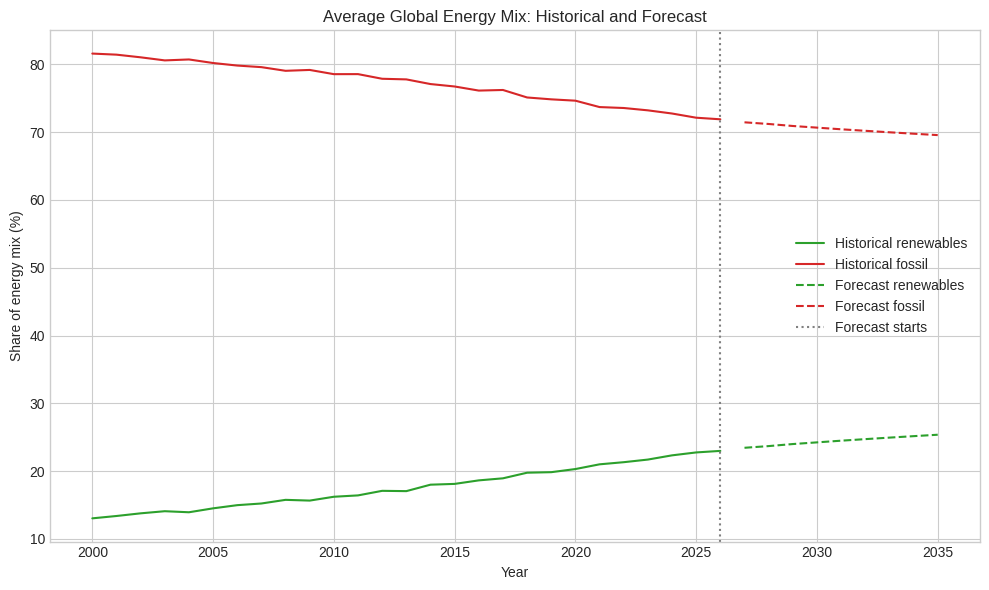

In [12]:
historical_average = energy.groupby("year")[["renewables_total_pct", "fossil_total_pct"]].mean().reset_index()
forecast_average = forecast.groupby("year")[["renewables_total_pct", "fossil_total_pct"]].mean().reset_index()
plt.figure(figsize=(10, 6))
plt.plot(historical_average.year, historical_average.renewables_total_pct, label="Historical renewables", color="#2ca02c")
plt.plot(historical_average.year, historical_average.fossil_total_pct, label="Historical fossil", color="#d62728")
plt.plot(forecast_average.year, forecast_average.renewables_total_pct, "--", label="Forecast renewables", color="#2ca02c")
plt.plot(forecast_average.year, forecast_average.fossil_total_pct, "--", label="Forecast fossil", color="#d62728")
plt.axvline(2026, color="gray", linestyle=":", label="Forecast starts")
plt.title("Average Global Energy Mix: Historical and Forecast")
plt.xlabel("Year")
plt.ylabel("Share of energy mix (%)")
plt.legend()
plt.tight_layout()
plt.show()

###📌5. Second model: Naive baseline

This baseline predicts each country's renewable share as the same as last year. It is used to check whether the Ridge model is better than a simple guess.

In [15]:
naive_pred = test["renewables_total_pct_lag1"]
naive_actual = test["renewables_total_pct"]
print(f"Naive baseline: MAE={mean_absolute_error(naive_actual, naive_pred):.3f}; "
      f"RMSE={mean_squared_error(naive_actual, naive_pred) ** 0.5:.3f}; "
      f"R2={r2_score(naive_actual, naive_pred):.3f}")

Naive baseline: MAE=1.835; RMSE=2.247; R2=0.966


## 7. Evaluate predictions on the test years

This section compares the predicted and actual renewable share for 2024–2026. Points close to the dashed line are accurate predictions. The chart is saved as `figure1_predicted_vs_actual.png` for the report.

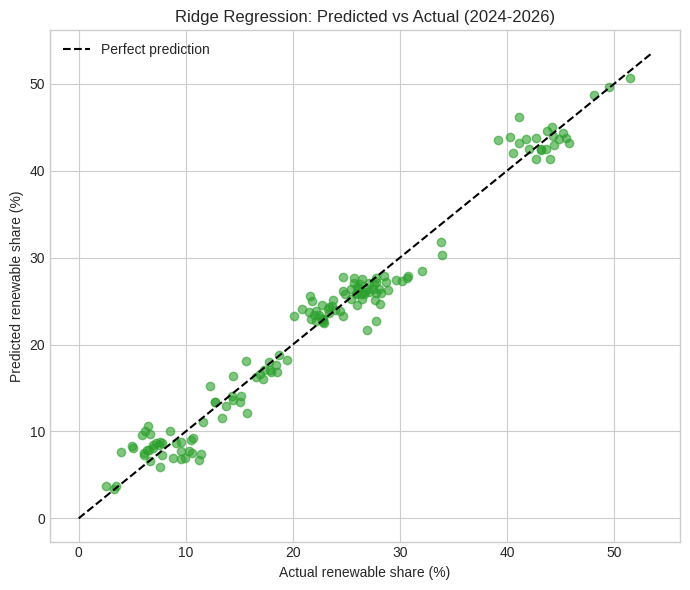

In [13]:
actual = test_predictions["renewables_total_pct"]
predicted = test_predictions["predicted_renewables_total_pct"]

plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.6, color="#2ca02c")
limits = [0, max(actual.max(), predicted.max()) + 2]
plt.plot(limits, limits, "k--", label="Perfect prediction")
plt.xlabel("Actual renewable share (%)")
plt.ylabel("Predicted renewable share (%)")
plt.title("Ridge Regression: Predicted vs Actual (2024-2026)")
plt.legend()
plt.tight_layout()
plt.savefig("figure1_predicted_vs_actual.png", dpi=200)
plt.show()

## 8. Identify key predictors and largest errors

This section shows the ten largest standardised Ridge coefficients (Figure 2), lists the countries with the largest average errors, and tests how much each feature group adds by comparing the test MAE with all features, with lag features only, and without lag features. The chart is saved as `figure2_top_predictors.png` for the report.

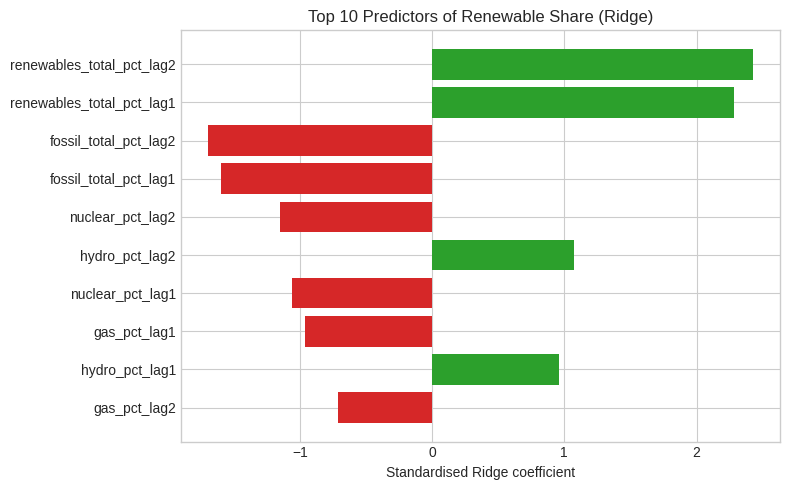

           abs_error  error
country                    
Qatar           3.30  -0.84
Australia       3.10  -3.10
Indonesia       2.88  -0.67
Morocco         2.83   0.53
Egypt           2.70   0.01
Iraq            2.62   0.11
Algeria         2.60   0.95
Malaysia        2.58  -0.81
MAE all features: 1.566
MAE lag features only: 1.508
MAE without lag features: 3.753


In [14]:
model = models["renewables_total_pct"]
names = list(model.named_steps["preprocessor"].named_transformers_["country"]
             .get_feature_names_out(["country"])) + feature_columns
coefs = pd.Series(model.named_steps["regressor"].coef_, index=names)[feature_columns]
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color=["#2ca02c" if v > 0 else "#d62728" for v in top.values])
plt.xlabel("Standardised Ridge coefficient")
plt.title("Top 10 Predictors of Renewable Share (Ridge)")
plt.tight_layout()
plt.savefig("figure3_top_predictors.png", dpi=200)
plt.show()

errors = test_predictions.copy()
errors["error"] = errors["predicted_renewables_total_pct"] - errors["renewables_total_pct"]
errors["abs_error"] = errors["error"].abs()
print(errors.groupby("country")[["abs_error", "error"]].mean()
      .sort_values("abs_error", ascending=False).head(8).round(2))

def test_mae(cols):
    pipe = Pipeline([("pre", ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), ["country"]),
                                                ("n", StandardScaler(), cols)])),
                     ("reg", Ridge(alpha=10.0))])
    pipe.fit(train[["country"] + cols], train["renewables_total_pct"])
    pred = np.clip(pipe.predict(test[["country"] + cols]), 0, 100)
    return mean_absolute_error(test["renewables_total_pct"], pred)

lag_only = [c for c in feature_columns if "lag" in c]
no_lag = [c for c in feature_columns if "lag" not in c]
print("MAE all features:", round(test_mae(feature_columns), 3))
print("MAE lag features only:", round(test_mae(lag_only), 3))
print("MAE without lag features:", round(test_mae(no_lag), 3))

## 📌9. Third model: Gradient Boosting

This section trains a Gradient Boosting model with the same features and the same time-based split as Ridge. The settings are tuned on the training years only (fit on 2000–2020, validate on 2021–2023), then the model is refit on 2000–2023 and tested on 2024–2026.

In [17]:

from itertools import product
from sklearn.ensemble import GradientBoostingRegressor

def make_pipe(**params):
    pre = ColumnTransformer([
        ("country", OneHotEncoder(handle_unknown="ignore"), ["country"]),
        ("numeric", StandardScaler(), feature_columns),
    ])
    return Pipeline([
        ("preprocessor", pre),
        ("regressor", GradientBoostingRegressor(random_state=42, **params))
    ])

# Tune using training and validation years
fit_part = train[train.year <= 2020]
val_part = train[train.year >= 2021]

grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.1]
}

results = []

for n, d, lr in product(
    grid["n_estimators"],
    grid["max_depth"],
    grid["learning_rate"]
):
    pipe = make_pipe(
        n_estimators=n,
        max_depth=d,
        learning_rate=lr
    )

    pipe.fit(
        fit_part[["country"] + feature_columns],
        fit_part["renewables_total_pct"]
    )

    pred = np.clip(
        pipe.predict(val_part[["country"] + feature_columns]),
        0, 100
    )

    mae = mean_absolute_error(
        val_part["renewables_total_pct"], pred
    )

    results.append((mae, n, d, lr))

best_mae, best_n, best_d, best_lr = min(results)

print(
    f"Best settings: n_estimators={best_n}, "
    f"max_depth={best_d}, learning_rate={best_lr}"
)
print(f"Validation MAE: {best_mae:.3f}")

# Train the final model through 2023
gb_model = make_pipe(
    n_estimators=best_n,
    max_depth=best_d,
    learning_rate=best_lr
)

gb_model.fit(
    train[["country"] + feature_columns],
    train["renewables_total_pct"]
)

gb_pred = np.clip(
    gb_model.predict(test[["country"] + feature_columns]),
    0, 100
)

gb_actual = test["renewables_total_pct"]

print("\nGradient Boosting Test Results")
print(f"MAE: {mean_absolute_error(gb_actual, gb_pred):.3f}")
print(f"RMSE: {mean_squared_error(gb_actual, gb_pred) ** 0.5:.3f}")
print(f"R²: {r2_score(gb_actual, gb_pred):.3f}")


Best settings: n_estimators=300, max_depth=2, learning_rate=0.03
Validation MAE: 1.435

Gradient Boosting Test Results
MAE: 1.750
RMSE: 2.167
R²: 0.968


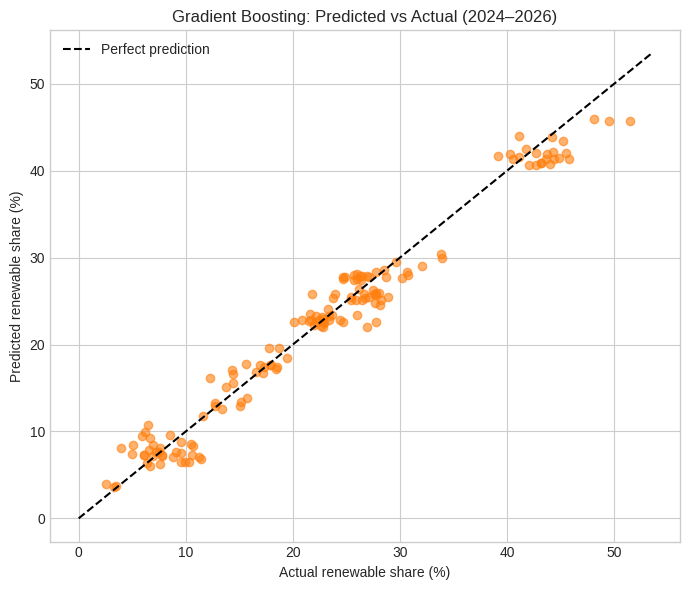

In [18]:
plt.figure(figsize=(7, 6))

plt.scatter(
    gb_actual,
    gb_pred,
    alpha=0.6,
    color="#ff7f0e"
)

limits = [
    0,
    max(gb_actual.max(), gb_pred.max()) + 2
]

plt.plot(
    limits,
    limits,
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual renewable share (%)")
plt.ylabel("Predicted renewable share (%)")
plt.title("Gradient Boosting: Predicted vs Actual (2024–2026)")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figure4_gradient_boosting_predicted_vs_actual.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



## 📌10. Fourth model: Random Forest

This section trains a Random Forest Regressor using the same features and time-based split as the previous models. Hyperparameters are selected using validation data from 2021–2023. The final model is evaluated on the held-out test years, 2024–2026.


In [19]:

from sklearn.ensemble import RandomForestRegressor

def make_rf_pipe(**params):
    pre = ColumnTransformer([
        ("country", OneHotEncoder(handle_unknown="ignore"), ["country"]),
        ("numeric", StandardScaler(), feature_columns),
    ])

    return Pipeline([
        ("preprocessor", pre),
        ("regressor", RandomForestRegressor(
            random_state=42,
            n_jobs=-1,
            **params
        ))
    ])

# Tune on training years only
rf_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 8, 16],
    "min_samples_leaf": [1, 3]
}

rf_results = []

for n, depth, leaf in product(
    rf_grid["n_estimators"],
    rf_grid["max_depth"],
    rf_grid["min_samples_leaf"]
):
    pipe = make_rf_pipe(
        n_estimators=n,
        max_depth=depth,
        min_samples_leaf=leaf
    )

    pipe.fit(
        fit_part[["country"] + feature_columns],
        fit_part["renewables_total_pct"]
    )

    val_pred = np.clip(
        pipe.predict(val_part[["country"] + feature_columns]),
        0, 100
    )

    val_mae = mean_absolute_error(
        val_part["renewables_total_pct"],
        val_pred
    )

    rf_results.append((val_mae, n, depth, leaf))

best_rf_mae, best_rf_n, best_rf_depth, best_rf_leaf = min(rf_results)

print(
    f"Best settings: n_estimators={best_rf_n}, "
    f"max_depth={best_rf_depth}, "
    f"min_samples_leaf={best_rf_leaf}"
)
print(f"Validation MAE: {best_rf_mae:.3f}")

# Train the final model through 2023
rf_model = make_rf_pipe(
    n_estimators=best_rf_n,
    max_depth=best_rf_depth,
    min_samples_leaf=best_rf_leaf
)

rf_model.fit(
    train[["country"] + feature_columns],
    train["renewables_total_pct"]
)

rf_pred = np.clip(
    rf_model.predict(test[["country"] + feature_columns]),
    0, 100
)

rf_actual = test["renewables_total_pct"]

print("\nRandom Forest Test Results")
print(f"MAE: {mean_absolute_error(rf_actual, rf_pred):.3f}")
print(f"RMSE: {mean_squared_error(rf_actual, rf_pred) ** 0.5:.3f}")
print(f"R²: {r2_score(rf_actual, rf_pred):.3f}")


Best settings: n_estimators=200, max_depth=8, min_samples_leaf=1
Validation MAE: 1.496

Random Forest Test Results
MAE: 1.887
RMSE: 2.359
R²: 0.962


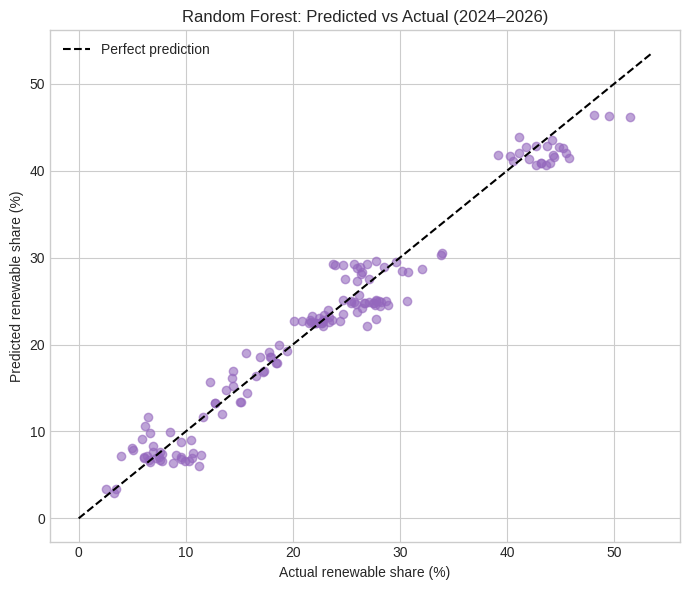

In [20]:
plt.figure(figsize=(7, 6))

plt.scatter(
    rf_actual,
    rf_pred,
    alpha=0.6,
    color="#9467bd"
)

limits = [
    0,
    max(rf_actual.max(), rf_pred.max()) + 2
]

plt.plot(
    limits,
    limits,
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual renewable share (%)")
plt.ylabel("Predicted renewable share (%)")
plt.title("Random Forest: Predicted vs Actual (2024–2026)")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figure5_random_forest_predicted_vs_actual.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



## 11. Compare All Four Models

This section compares the Naive Baseline, Ridge Regression, Gradient Boosting, and Random Forest using MAE, RMSE, and R² on the same test observations from 2024–2026.


In [26]:
comparison_actual = test["renewables_total_pct"].to_numpy()

comparison_predictions = {
    "Naive Baseline": test["renewables_total_pct_lag1"].to_numpy(),
    "Ridge Regression": test_predictions[
        "predicted_renewables_total_pct"
    ].to_numpy(),
    "Gradient Boosting": gb_pred,
    "Random Forest": rf_pred
}

metric_rows = []

for name, pred in comparison_predictions.items():
    metric_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(comparison_actual, pred),
        "RMSE": mean_squared_error(comparison_actual, pred) ** 0.5,
        "R²": r2_score(comparison_actual, pred)
    })

comparison_df = pd.DataFrame(metric_rows).sort_values("MAE")

display(comparison_df.round(3))


,Model,MAE,RMSE,R²
1,Ridge Regression,1.566,1.985,0.973
2,Gradient Boosting,1.750,2.167,0.968
0,Naive Baseline,1.835,2.247,0.966
3,Random Forest,1.887,2.359,0.962


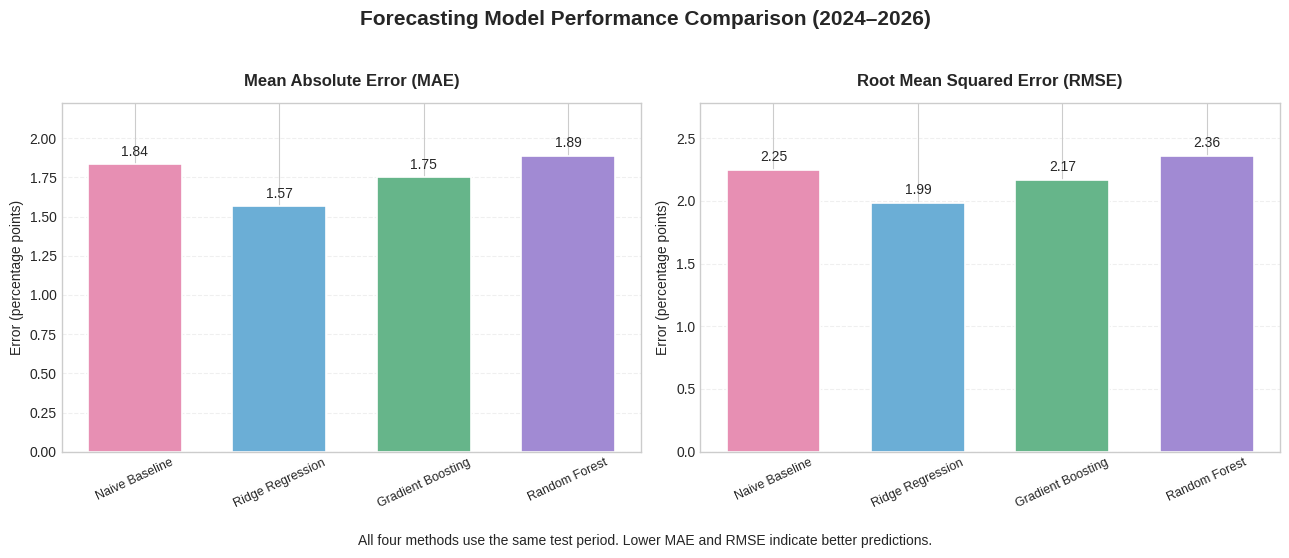

In [28]:
model_order = [
    "Naive Baseline",
    "Ridge Regression",
    "Gradient Boosting",
    "Random Forest"
]

plot_df = comparison_df.set_index("Model").loc[model_order]

model_colors = {
    "Naive Baseline": "#E78FB3",       # Pink
    "Ridge Regression": "#6BAED6",     # Blue
    "Gradient Boosting": "#66B58A",    # Green
    "Random Forest": "#A18AD3"         # Purple
}

colors = [model_colors[name] for name in model_order]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = [
    ("MAE", "Mean Absolute Error (MAE)"),
    ("RMSE", "Root Mean Squared Error (RMSE)")
]

for ax, (metric, title) in zip(axes, metrics):
    values = plot_df[metric]

    bars = ax.bar(
        model_order,
        values,
        color=colors,
        width=0.65,
        edgecolor="white",
        linewidth=1.2
    )

    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Error (percentage points)")
    ax.tick_params(axis="x", rotation=25, labelsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Add score labels above each bar
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=10)

    ax.set_ylim(0, max(values) * 1.18)

fig.suptitle(
    "Forecasting Model Performance Comparison (2024–2026)",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

fig.text(
    0.5, -0.04,
    "All four methods use the same test period. Lower MAE and RMSE indicate better predictions.",
    ha="center",
    fontsize=10
)

plt.tight_layout()
plt.savefig(
    "figure6_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
